Лабораторна робота 2. Сапун , 4-9
---



# Завдання 1

**Був присутній на парі**

Обробка та нааліз даних про ВВП країн. Датасет було отримано з Вікіпедії з використанням бібілотеки Pandas.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests
from io import StringIO

url = "https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)"

headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/152.0 Safari/537.36"
}

response = requests.get(url, headers=headers)

html = StringIO(response.text)
tables = pd.read_html(html)

for table in tables:
    columns_text = " ".join(map(str, table.columns))

    if "IMF" in columns_text and "World Bank" in columns_text:
        df = table.copy()
        break

if isinstance(df.columns, pd.MultiIndex):
    df.columns = [
        " ".join(
            str(x) for x in col
            if "Unnamed" not in str(x)
        ).strip()
        for col in df.columns
    ]

print(df.columns)
display(df.head())

Index(['Country/Territory', 'IMF (2026)[1]', 'World Bank (2025)[6]',
       'United Nations (2024)[7]'],
      dtype='object')


,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


1. Вивести перші 5 рядків датасета

In [26]:
df.head()

,Country/Territory,IMF (2026)[1],World Bank (2025)[6],United Nations (2024)[7]
0,World,126295331,118350166,111565144
1,United States,32383920,30769700,29298000
2,China[n 1],20851593,19498039,18743802
3,Germany,5452858,5050923,4659929
4,Japan,4379253,4435163,4026211


2.	Визначити розмір датасета.

In [27]:
print("Розмір датасета:", df.shape)
print("Кількість рядків:", df.shape[0])
print("Кількість стовпців:", df.shape[1])

Розмір датасета: (222, 4)
Кількість рядків: 222
Кількість стовпців: 4


 3.	Визначити оптимальну кількість стовпців (видалити зайві, на власний розсуд).

In [28]:
country_col = next(col for col in df.columns if "Country" in col)
imf_col = next(col for col in df.columns if "IMF" in col)
wb_col = next(col for col in df.columns if "World Bank" in col)
un_col = next(col for col in df.columns if "United Nations" in col)

df = df[[country_col, imf_col, wb_col, un_col]]

df.columns = [
    "Country",
    "IMF_2026",
    "World_Bank_2025",
    "United_Nations_2024"
]
df = df[df["Country"] != "World"].reset_index(drop=True)

df.head()

,Country,IMF_2026,World_Bank_2025,United_Nations_2024
0,United States,32383920,30769700,29298000
1,China[n 1],20851593,19498039,18743802
2,Germany,5452858,5050923,4659929
3,Japan,4379253,4435163,4026211
4,United Kingdom,4264794,4002588,3685881


4.	Замініть у таблиці значення "—" на значення NaN. Перевірити наявність пропущених значень. При наявності, замінити пропущені значення на середнє значення.

In [29]:
numeric_columns = [
    "IMF_2026",
    "World_Bank_2025",
    "United_Nations_2024"
]

for col in numeric_columns:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", "", regex=False)
        .str.extract(r"([0-9]+(?:\.[0-9]+)?)", expand=False)
    )

    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Пропущені значення до заповнення:")
print(df.isnull().sum())

Пропущені значення до заповнення:
Country                 0
IMF_2026               24
World_Bank_2025         7
United_Nations_2024     9
dtype: int64


In [30]:
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].mean())

print("Пропущені значення після заповнення:")
print(df.isnull().sum())

Пропущені значення після заповнення:
Country                0
IMF_2026               0
World_Bank_2025        0
United_Nations_2024    0
dtype: int64


5. Ще раз вивести датасет

In [31]:
df

,Country,IMF_2026,World_Bank_2025,United_Nations_2024
0,United States,3.238392e+07,3.076970e+07,29298000.0
1,China[n 1],2.085159e+07,1.949804e+07,18743802.0
2,Germany,5.452858e+06,5.050923e+06,4659929.0
3,Japan,4.379253e+06,4.435163e+06,4026211.0
4,United Kingdom,4.264794e+06,4.002588e+06,3685881.0
...,...,...,...,...
216,Palau,3.770000e+02,3.450000e+02,310.0
217,Marshall Islands,3.420000e+02,3.080000e+02,281.0
218,Nauru,1.960000e+02,1.760000e+02,187.0
219,Montserrat,6.412000e+05,5.482661e+05,81.0


6.	Перевірити наявність дублікатів. При наявності видалити дублікати.

In [32]:
print("Кількість дублікатів:", df.duplicated().sum())

Кількість дублікатів: 0


In [33]:
duplicates = df[df.duplicated()]

duplicates

,Country,IMF_2026,World_Bank_2025,United_Nations_2024


In [34]:
df = df.drop_duplicates().reset_index(drop=True)

print("Кількість дублікатів після видалення:", df.duplicated().sum())

Кількість дублікатів після видалення: 0


7.	Вивести описову статистику датасету describe()

In [35]:
df[numeric_columns].describe()

,IMF_2026,World_Bank_2025,United_Nations_2024
count,2.210000e+02,2.210000e+02,2.210000e+02
mean,6.412000e+05,5.482661e+05,5.224912e+05
std,2.668734e+06,2.528406e+06,2.410079e+06
min,6.500000e+01,5.700000e+01,5.600000e+01
25%,1.733600e+04,9.194000e+03,8.840000e+03
50%,8.383200e+04,4.549000e+04,4.276500e+04
75%,5.799960e+05,3.062390e+05,2.986970e+05
max,3.238392e+07,3.076970e+07,2.929800e+07


8. Визначте відхилення (різницю) між показниками IMF (2026) та World Bank (2025) для кожної країни. У яких країнах ці показники найбільше відрізняються (дати відповідь)?

In [36]:
df["IMF_WB_difference"] = abs(
    df["IMF_2026"] - df["World_Bank_2025"]
)

result8 = df[
    ["Country", "IMF_2026", "World_Bank_2025", "IMF_WB_difference"]
].sort_values(
    by="IMF_WB_difference",
    ascending=False
)

print("Країни з найбільшою різницею:")
result8.head(10)

Країни з найбільшою різницею:


,Country,IMF_2026,World_Bank_2025,IMF_WB_difference
0,United States,3.238392e+07,30769700.0,1.614220e+06
1,China[n 1],2.085159e+07,19498039.0,1.353554e+06
211,Saint Martin,6.412000e+05,649.0,6.405510e+05
208,American Samoa,6.412000e+05,871.0,6.403290e+05
207,Northern Mariana Islands,6.412000e+05,1096.0,6.401040e+05
200,Turks and Caicos Islands,6.412000e+05,1745.0,6.394550e+05
196,Sint Maarten,6.412000e+05,1888.0,6.393120e+05
183,Greenland,6.412000e+05,3327.0,6.378730e+05
181,Curaçao,6.412000e+05,3561.0,6.376390e+05
179,Faroe Islands,6.412000e+05,4053.0,6.371470e+05


9.	Обчисліть кореляцію між показниками IMF (2026), World Bank (2025) та United Nations (2024). Які пари змінних мають найвищу кореляцію?

In [37]:
correlation = df[numeric_columns].corr()

correlation

,IMF_2026,World_Bank_2025,United_Nations_2024
IMF_2026,1.000000,0.997809,0.998046
World_Bank_2025,0.997809,1.000000,0.998378
United_Nations_2024,0.998046,0.998378,1.000000


In [38]:
mask = np.triu(np.ones(correlation.shape), k=1).astype(bool)

pairs = (
    correlation
    .where(mask)
    .stack()
    .sort_values(ascending=False)
)

print("Кореляція між парами показників:")
print(pairs)

print("\nНайвища кореляція:")
print(pairs.head(1))

Кореляція між парами показників:
World_Bank_2025  United_Nations_2024    0.998378
IMF_2026         United_Nations_2024    0.998046
                 World_Bank_2025        0.997809
dtype: float64

Найвища кореляція:
World_Bank_2025  United_Nations_2024    0.998378
dtype: float64


Обчислити середнє значення за стовпцями

In [39]:
print("Середнє IMF 2026:")
print(df["IMF_2026"].mean())

Середнє IMF 2026:
641200.0304568529


In [40]:
print("Середнє World Bank 2025:")
print(df["World_Bank_2025"].mean())

Середнє World Bank 2025:
548266.0607476636


In [41]:
print("Середнє United Nations 2024:")
print(df["United_Nations_2024"].mean())

Середнє United Nations 2024:
522491.2075471698


11.	Обчисліть стандартне відхилення показників для кожної країни. Яка країна має найвищу варіативність у показниках між роками?

In [42]:
df["Standard_Deviation"] = df[numeric_columns].std(axis=1)

result11 = df[
    ["Country", "Standard_Deviation"]
].sort_values(
    by="Standard_Deviation",
    ascending=False
)

print("Країни з найбільшою варіативністю:")
display(result11.head(10))

print(
    "\nНайбільшу варіативність має:",
    result11.iloc[0]["Country"]
)

Країни з найбільшою варіативністю:


,Country,Standard_Deviation
0,United States,1.543508e+06
1,China[n 1],1.068002e+06
2,Germany,3.964771e+05
200,Turks and Caicos Islands,3.691861e+05
196,Sint Maarten,3.691699e+05
183,Greenland,3.682360e+05
181,Curaçao,3.681411e+05
170,French Polynesia,3.665461e+05
165,Cayman Islands,3.657451e+05
160,New Caledonia,3.652612e+05



Найбільшу варіативність має: United States


12.	Визначення країни з найвищим та найнижчим показниками: Знайдіть країну з найвищим та найнижчим показниками у кожному з років (IMF (2026), World Bank (2025), United Nations (2024)).

In [43]:
for col in numeric_columns:

    max_index = df[col].idxmax()
    min_index = df[col].idxmin()

    print("\n", col)

    print(
        "Найбільше значення:",
        df.loc[max_index, "Country"],
        "-",
        df.loc[max_index, col]
    )

    print(
        "Найменше значення:",
        df.loc[min_index, "Country"],
        "-",
        df.loc[min_index, col]
    )


 IMF_2026
Найбільше значення: United States - 32383920.0
Найменше значення: Tuvalu - 65.0

 World_Bank_2025
Найбільше значення: United States - 30769700.0
Найменше значення: Tuvalu - 57.0

 United_Nations_2024
Найбільше значення: United States - 29298000.0
Найменше значення: Tuvalu - 56.0


13.	Побудуйте гістограму для розподілу показників IMF (2026) серед всіх країн. Який вигляд має розподіл? Чи є країни, що виділяються?

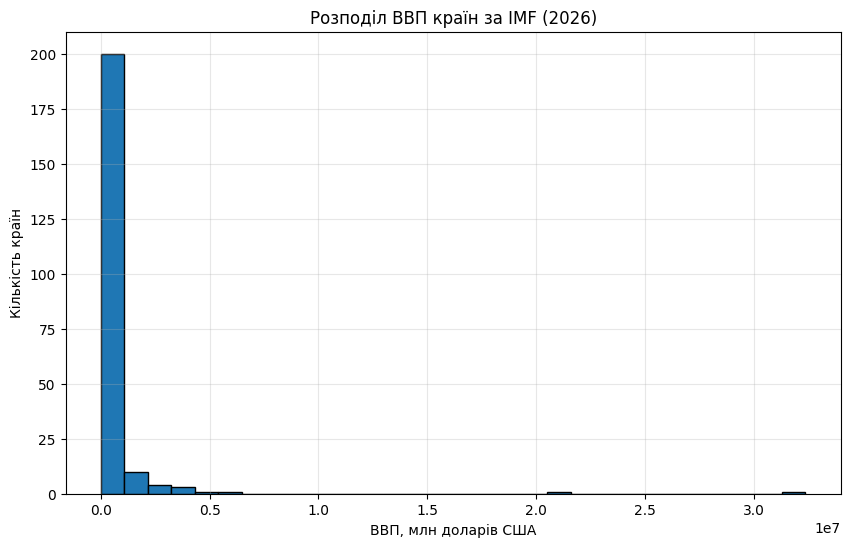

In [44]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["IMF_2026"],
    bins=30,
    edgecolor="black"
)

plt.title("Розподіл ВВП країн за IMF (2026)")
plt.xlabel("ВВП, млн доларів США")
plt.ylabel("Кількість країн")

plt.grid(alpha=0.3)

plt.show()

14.	Розрахуйте частку кожної країни в загальному значенні для кожного року (IMF (2026), World Bank (2025), United Nations (2024)).
 Як змінюються частки країн з часом (дати відповідь)?

In [45]:
Q1 = df["IMF_2026"].quantile(0.25)
Q3 = df["IMF_2026"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["IMF_2026"] < lower) |
    (df["IMF_2026"] > upper)
]

print("Країни, що виділяються:")
display(
    outliers[
        ["Country", "IMF_2026"]
    ].sort_values("IMF_2026", ascending=False)
)

print(
    "\nВисновок: розподіл має сильну правосторонню асиметрію. "
    "Більшість країн мають відносно невеликий ВВП, "
    "а найбільші економіки значно виділяються."
)

Країни, що виділяються:


,Country,IMF_2026
0,United States,32383920.0
1,China[n 1],20851593.0
2,Germany,5452858.0
3,Japan,4379253.0
4,United Kingdom,4264794.0
5,India,4153191.0
6,France,3596094.0
7,Italy,2738164.0
8,Russia,2656452.0
9,Brazil,2635912.0



Висновок: розподіл має сильну правосторонню асиметрію. Більшість країн мають відносно невеликий ВВП, а найбільші економіки значно виділяються.


15.	Візуалізуйте зміни в показниках для кожної країни за три роки на графіку. Які країни показують стабільне зростання або спад (дати відповідь)?

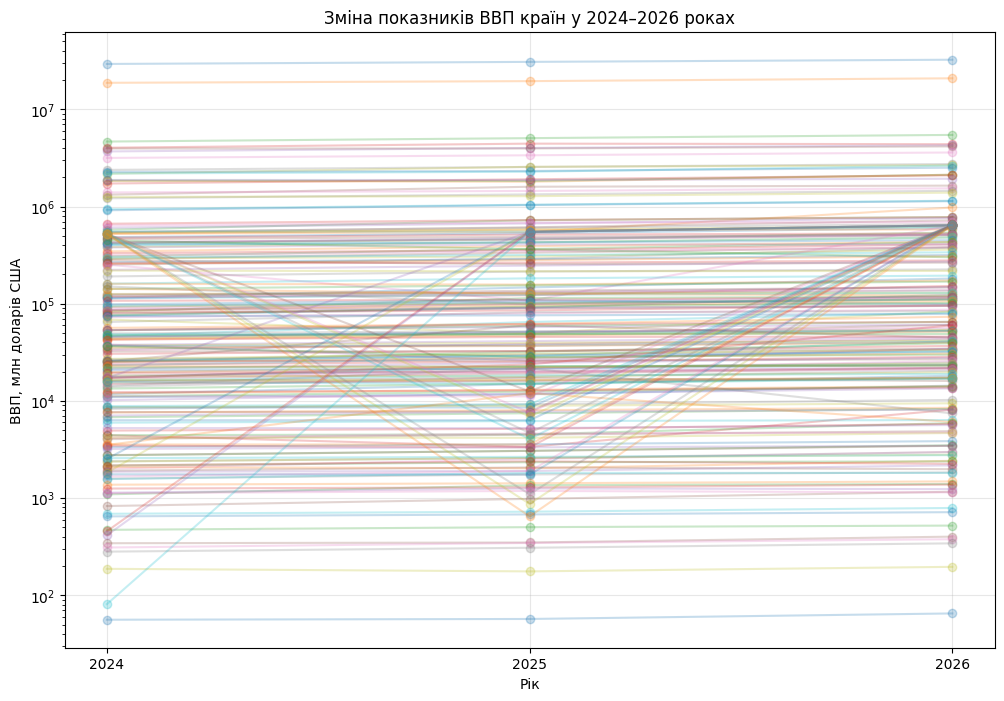

In [46]:
years = [2024, 2025, 2026]

plt.figure(figsize=(12, 8))

for _, row in df.iterrows():
    values = [
        row["United_Nations_2024"],
        row["World_Bank_2025"],
        row["IMF_2026"]
    ]

    plt.plot(
        years,
        values,
        marker="o",
        alpha=0.25
    )

plt.yscale("log")

plt.title("Зміна показників ВВП країн у 2024–2026 роках")
plt.xlabel("Рік")
plt.ylabel("ВВП, млн доларів США")

plt.xticks(years)
plt.grid(alpha=0.3)

plt.show()

In [47]:
growth = df[
    (df["United_Nations_2024"] < df["World_Bank_2025"]) &
    (df["World_Bank_2025"] < df["IMF_2026"])
]

decline = df[
    (df["United_Nations_2024"] > df["World_Bank_2025"]) &
    (df["World_Bank_2025"] > df["IMF_2026"])
]

print("Країни зі стабільним зростанням:")
print(", ".join(growth["Country"].tolist()))

print("\nКраїни зі стабільним спадом:")
print(", ".join(decline["Country"].tolist()))

print("\nКількість країн зі зростанням:", len(growth))
print("Кількість країн зі спадом:", len(decline))

Країни зі стабільним зростанням:
United States, China[n 1], Germany, United Kingdom, India, France, Italy, Russia, Brazil, Canada, Spain, Turkey, Indonesia, Netherlands, Saudi Arabia, Switzerland, Poland, Taiwan[n 3], Ireland, Belgium, Sweden, Israel, Argentina, Singapore, Austria, Norway, Thailand, Colombia, Vietnam, Malaysia, Philippines, Bangladesh, Denmark, Romania, South Africa, Hong Kong[n 4], Czech Republic, Egypt, Chile, Pakistan, Peru, Portugal, Nigeria, Kazakhstan, Finland, Algeria, Greece, New Zealand, Hungary, Ukraine[n 5], Morocco, Uzbekistan, Slovakia, Angola, Bulgaria, Kenya, Ecuador, Dominican Republic, Guatemala, DR Congo, Ghana, Oman, Croatia, Ivory Coast, Serbia, Luxembourg, Costa Rica, Lithuania, Belarus, Uruguay, Panama, Tanzania[n 6], Slovenia, Myanmar, Bolivia, Azerbaijan, Uganda, Cameroon, Jordan, Tunisia, Paraguay, Zimbabwe, Macau[n 7], Latvia, Cambodia, Estonia, Nepal, Cyprus[n 8], Iceland, Georgia[n 9], Honduras, Zambia, Senegal, El Salvador, Haiti, Bosnia an

In [50]:
shares = df[[
    "Country",
    "IMF_2026",
    "World_Bank_2025",
    "United_Nations_2024"
]].copy()

shares["IMF_2026_share_%"] = (
    shares["IMF_2026"] / shares["IMF_2026"].sum()
) * 100

shares["World_Bank_2025_share_%"] = (
    shares["World_Bank_2025"] / shares["World_Bank_2025"].sum()
) * 100

shares["UN_2024_share_%"] = (
    shares["United_Nations_2024"] / shares["United_Nations_2024"].sum()
) * 100

shares.sort_values(
    by="IMF_2026_share_%",
    ascending=False
).head(15)

,Country,IMF_2026,World_Bank_2025,United_Nations_2024,IMF_2026_share_%,World_Bank_2025_share_%,UN_2024_share_%
0,United States,32383920.0,30769700.0,29298000.0,22.853021,25.394498,25.372702
1,China[n 1],20851593.0,19498039.0,18743802.0,14.714768,16.091899,16.232538
2,Germany,5452858.0,5050923.0,4659929.0,3.848029,4.168570,4.035599
3,Japan,4379253.0,4435163.0,4026211.0,3.090397,3.660378,3.486786
4,United Kingdom,4264794.0,4002588.0,3685881.0,3.009624,3.303370,3.192053
5,India,4153191.0,3956067.0,3952244.0,2.930867,3.264976,3.422729
6,France,3596094.0,3366316.0,3160443.0,2.537729,2.778250,2.737012
7,Italy,2738164.0,2551557.0,2380825.0,1.932296,2.105822,2.061846
8,Russia,2656452.0,2561310.0,2173386.0,1.874633,2.113871,1.882199
9,Brazil,2635912.0,2279920.0,2185822.0,1.860138,1.881638,1.892969
